# Phase 2, M0 pilot: light curves, detrending and views (10/19/2026)

The user approved the Phase 2 recommendations D1–D7 (`PHASE2_PLAN.md`) today. This notebook checks the M0 pilot:
49 **pool** stars (no test stars), chosen to cover every class, were downloaded from MAST into the compact cache,
detrended, and turned into views for each of their KOIs (`sweeps/p2_pilot.jl`).

**M0 gate:** the pipeline works end to end, the size/time estimate for the full download is confirmed, and the
views look right by eye.

Labels and robovetter flags appear here only to pick and name the example stars. They are never model inputs.

In [1]:
include(joinpath(@__DIR__, "..", "src", "VettingSetup.jl"))
df_raw = load_koi()
df = clean_koi(df_raw)
pool, test = cv_pool(df)
picks = CSV.read(joinpath(CV_DIR, "p2_pilot_stars.csv"), DataFrame)
views = JLD2.load(joinpath(LC_DIR, "pilot_views.jld2"))["views"]
@printf("%d pilot stars, %d KOIs with views; any test star among them: %s\n", nrow(picks), length(views),
        any(in(Set(test.kepid)), picks.kepid))
combine(groupby(picks, :category), nrow => :stars)

VettingSetup loaded:11 features, data at C:\JuliaProjects\Exoplanet vetting\data\koi_cumulative.csv
┌ Info: clean_koi
│   raw = 9564
│   kept = 9201
│   stars = 7927
│   planets = 4619
└   false_pos = 4582
49 pilot stars, 71 KOIs with views; any test star among them: false


Row,category,stars
,DataStri…,Int64
1,CONFIRMED,8
2,CANDIDATE,6
3,FP: SS (EB),7
4,FP: CO (offset),7
5,FP: NT,7
6,FP: EC,4
7,USP planet,3
8,Long-P planet,3
9,Supplemental planet,2


## 1. Size and time: extrapolation to the full download (M1)
Measured on the pilot, then scaled to all 7,927 stars of the cleaned catalog. Download time is per star, one star
at a time with 4 parallel file requests.

In [2]:
timing = CSV.read(joinpath(CV_DIR, "p2_pilot_timing.csv"), DataFrame)
DataFrame(quantity = names(timing), value = [round(x; sigdigits = 4) for x in timing[1, :]])

Row,quantity,value
,String,Float64
1,stars_ok,49.0
2,stars_tried,49.0
3,raw_mb_per_star,6.922
4,cache_mb_per_star,1.856
5,dl_s_per_star,1.045
6,views_s_per_star,1.406
7,n_kois,71.0
8,all_stars,7927.0
9,est_raw_gb,54.87


## 2. Raw vs detrended light curves
Top of each panel: PDCSAP flux normalised per quarter (grey) with the biweight trend (red), fitted with every KOI's
transits masked. Bottom: the flattened light curve with the KOI's transit times marked.

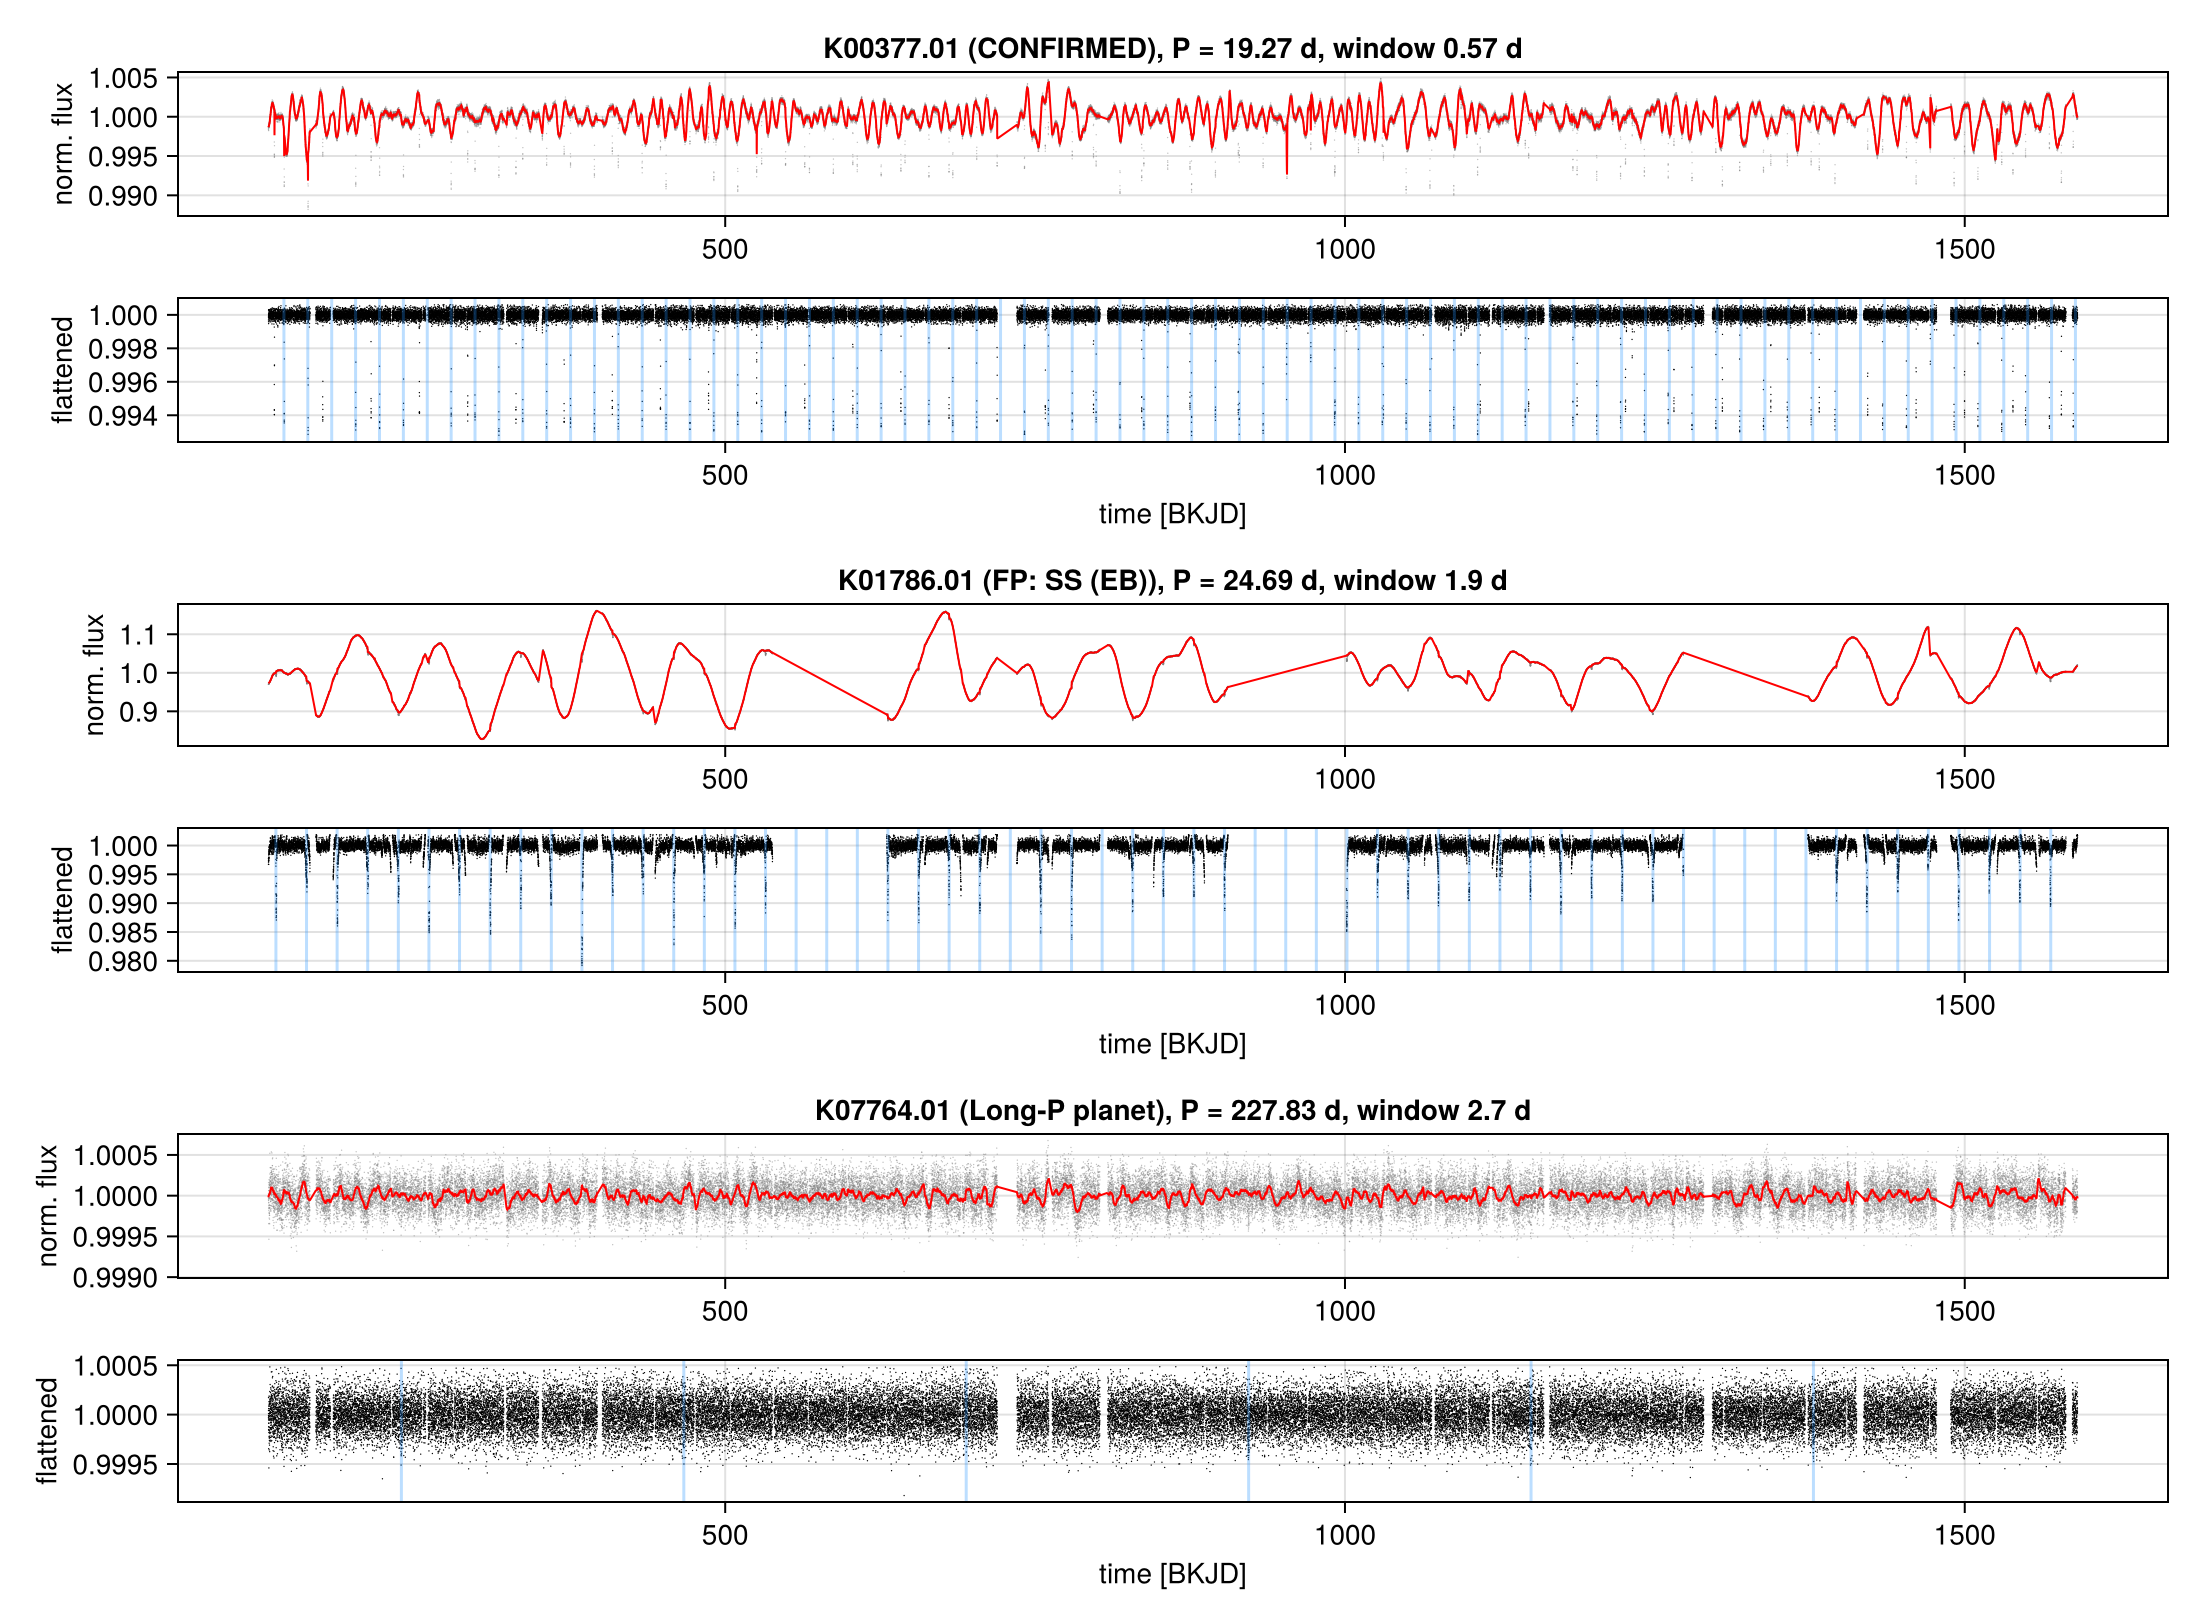

In [3]:
first_koi(cat) = picks.kepoi_name[findfirst(==(cat), picks.category)]
function plot_detrend(names)
    fig = Figure(size = (1100, 270 * length(names)))
    for (i, n) in enumerate(names)
        k = df_raw.kepid[findfirst(==(n), df_raw.kepoi_name)]
        ephs = star_ephemerides(df_raw, k)
        d = detrend_lc(load_lc(k), ephs)
        e = only(filter(x -> x.name == n, ephs))
        cat = picks.category[findfirst(==(k), picks.kepid)]
        ax1 = Axis(fig[2i-1, 1]; title = "$n ($cat), P = $(round(e.period; digits = 2)) d, window $(round(d.window; digits = 2)) d",
                   ylabel = "norm. flux")
        scatter!(ax1, d.time, d.raw; markersize = 1, color = (:grey, 0.5))
        lines!(ax1, d.time, d.trend; color = :red, linewidth = 1)
        ax2 = Axis(fig[2i, 1]; xlabel = "time [BKJD]", ylabel = "flattened")
        scatter!(ax2, d.time, d.flux; markersize = 1, color = :black)
        tt = e.t0 .+ e.period .* (ceil((d.time[1] - e.t0) / e.period):floor((d.time[end] - e.t0) / e.period))
        length(tt) < 300 && vlines!(ax2, tt; color = (:dodgerblue, 0.3))
        linkxaxes!(ax1, ax2)
    end
    fig
end
plot_detrend([first_koi("CONFIRMED"), first_koi("FP: SS (EB)"), first_koi("Long-P planet")])

## 3. Views for one KOI of each class
Columns: global view (whole orbit, phase in units of the period), local view (±2 durations), odd (blue) vs even
(orange) transits, and the view around the deepest off-transit dip ("secondary"). All are on the local view's scale
(out of transit 0, transit minimum −1), so a secondary at −0.3 means 30% of the primary depth.

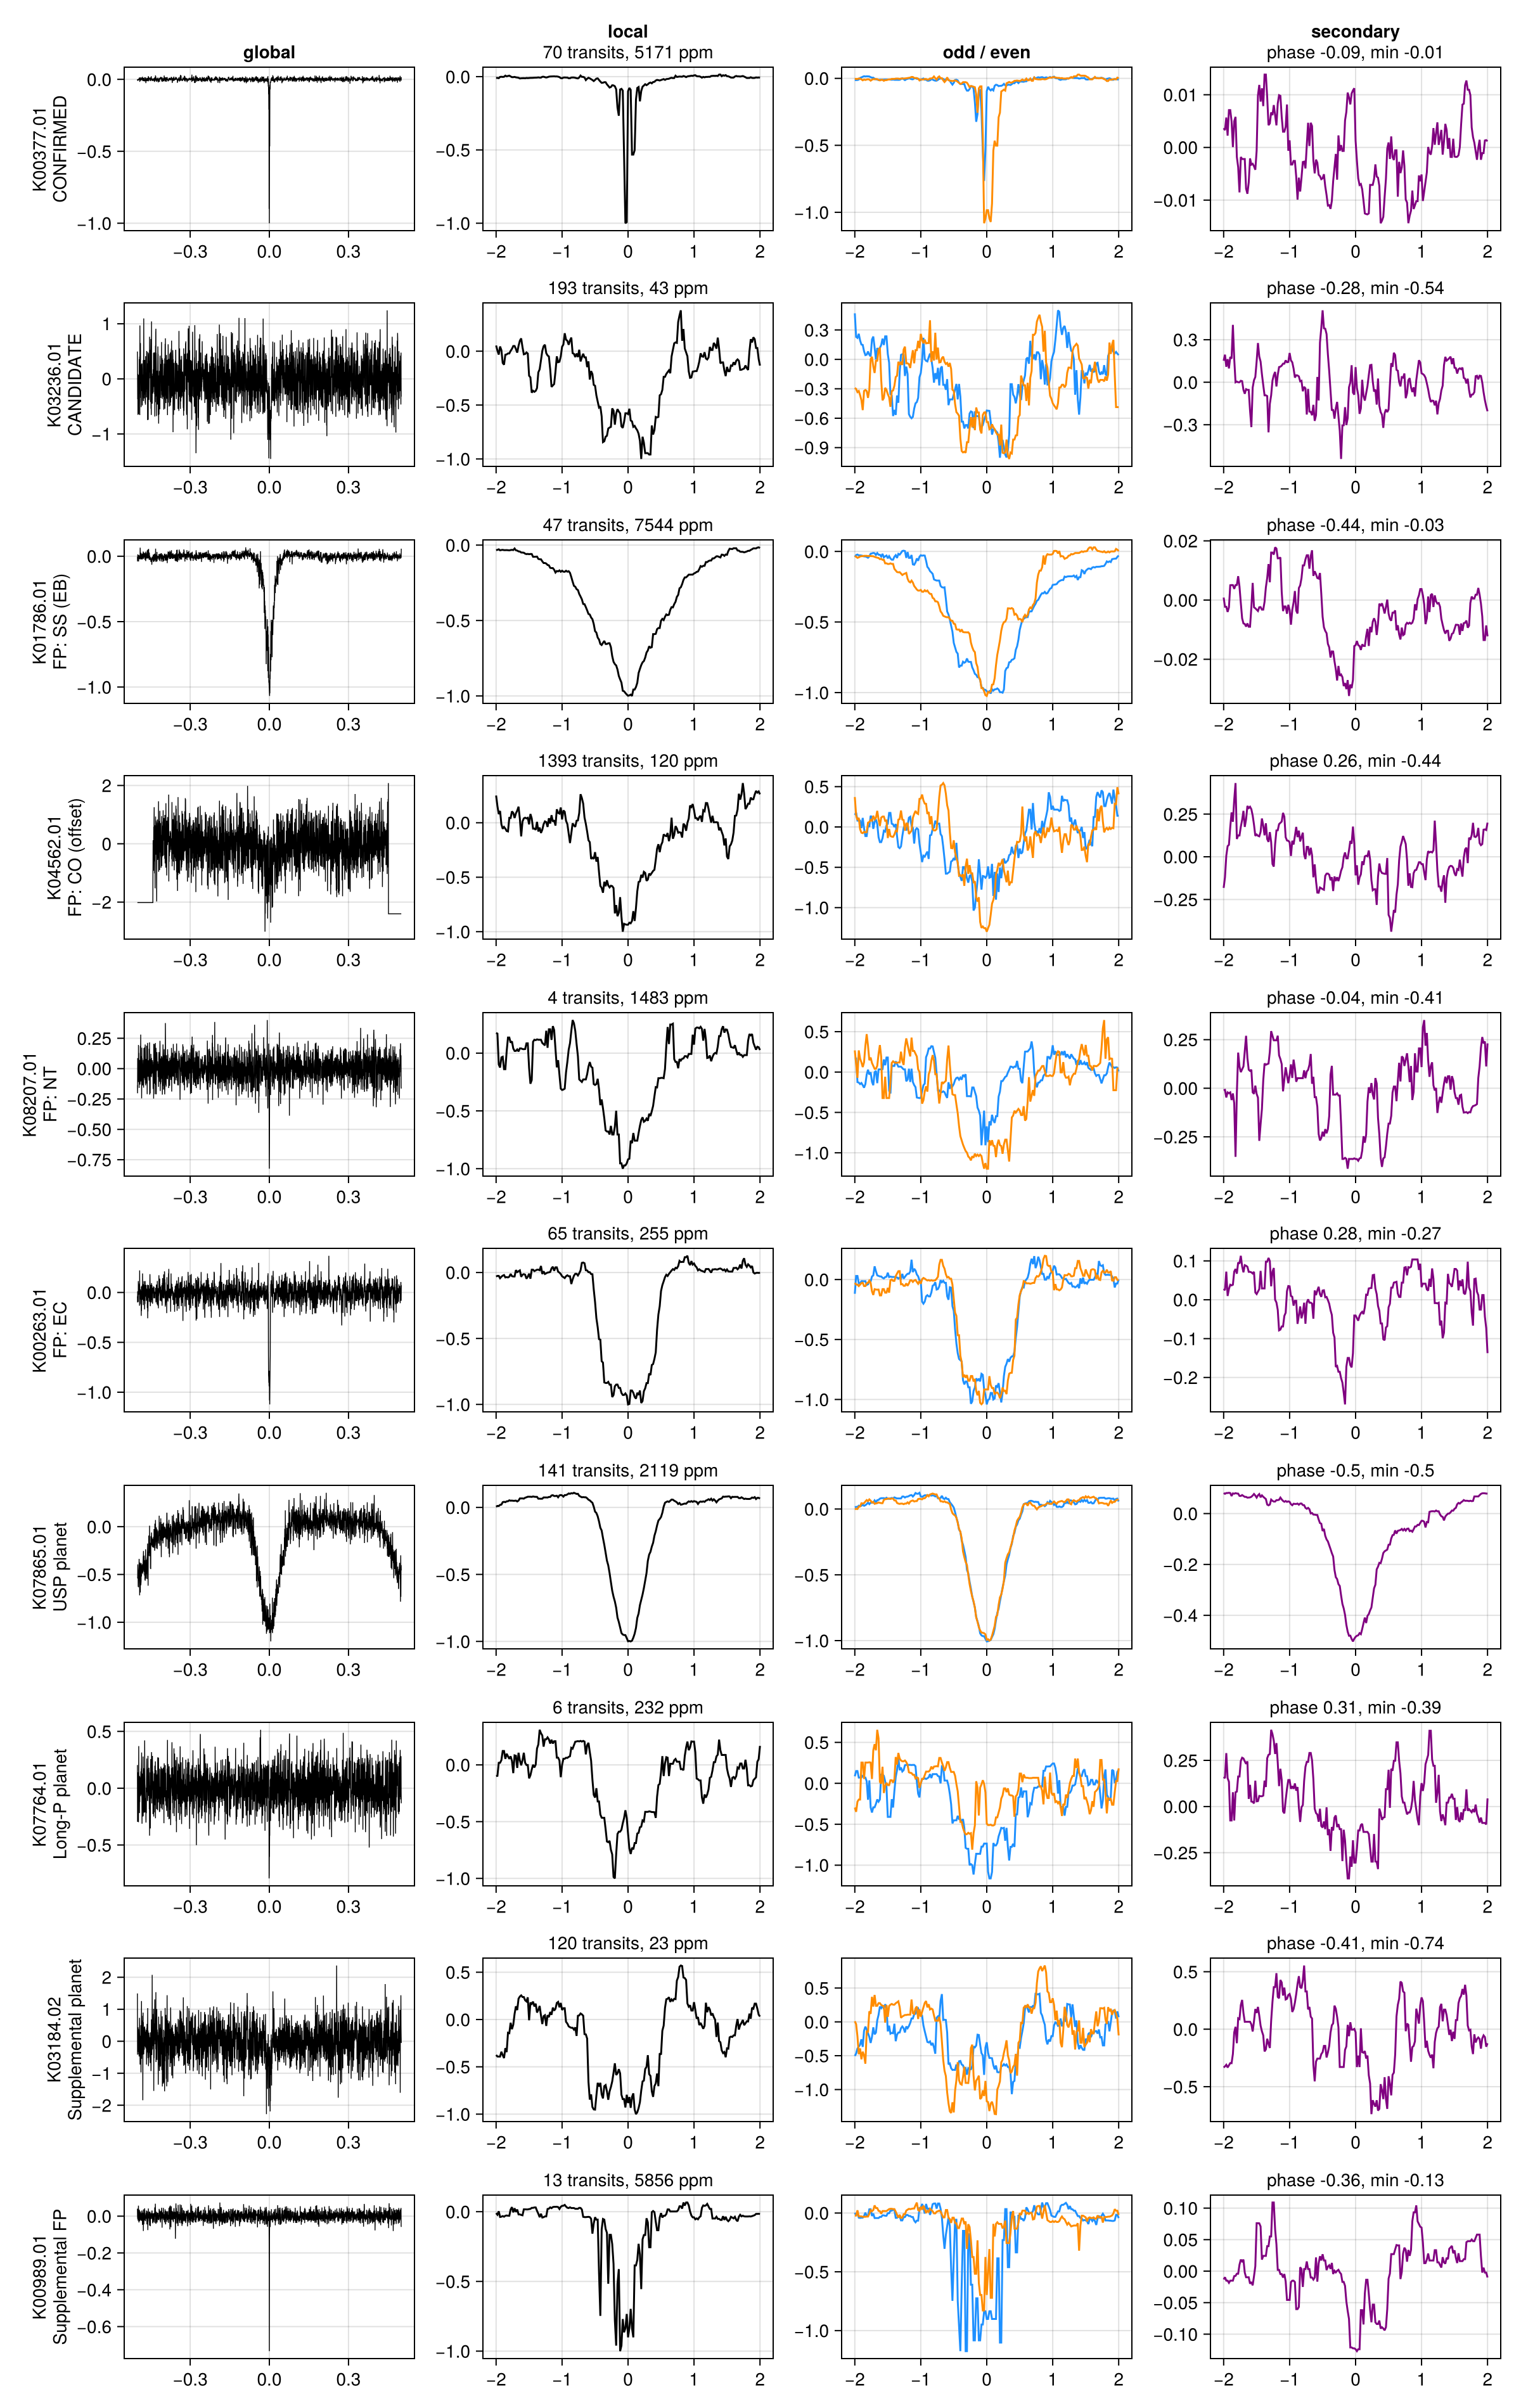

In [4]:
function plot_views(names)
    fig = Figure(size = (1200, 190 * length(names)))
    xl = range(-LOCAL_SPAN, LOCAL_SPAN; length = N_LOCAL); xg = range(-0.5, 0.5; length = N_GLOBAL)
    for (i, n) in enumerate(names)
        v = views[n]
        cat = picks.category[findfirst(==(n), picks.kepoi_name)]
        a = [Axis(fig[i, j]) for j in 1:4]
        lines!(a[1], xg, v.global_view; color = :black, linewidth = 0.7)
        lines!(a[2], xl, v.local_view; color = :black)
        lines!(a[3], xl, v.odd; color = :dodgerblue); lines!(a[3], xl, v.even; color = :darkorange)
        lines!(a[4], xl, v.secondary; color = :purple)
        a[1].ylabel = "$n\n$cat"
        a[4].title = i == 1 ? "secondary" : ""
        a[4].subtitle = isnan(v.sec_phase) ? "" : "phase $(round(v.sec_phase; digits = 2)), min $(round(minimum(v.secondary); digits = 2))"
        a[2].subtitle = "$(v.n_transits) transits, $(round(Int, 1e6 * v.depth)) ppm"
        if i == 1
            a[1].title = "global"; a[2].title = "local"; a[3].title = "odd / even"
        end
    end
    fig
end
example_cats = ["CONFIRMED", "CANDIDATE", "FP: SS (EB)", "FP: CO (offset)", "FP: NT", "FP: EC", "USP planet",
                "Long-P planet", "Supplemental planet", "Supplemental FP"]
plot_views(first_koi.(example_cats))

## 4. Average local and secondary views per class (pilot stars only)
The M2 gate asks for this on the whole pool; the pilot gives a first look. Expect planets to be U-shaped with no
secondary, and eclipsing binaries (SS) to be V-shaped, often with a secondary and odd/even differences.

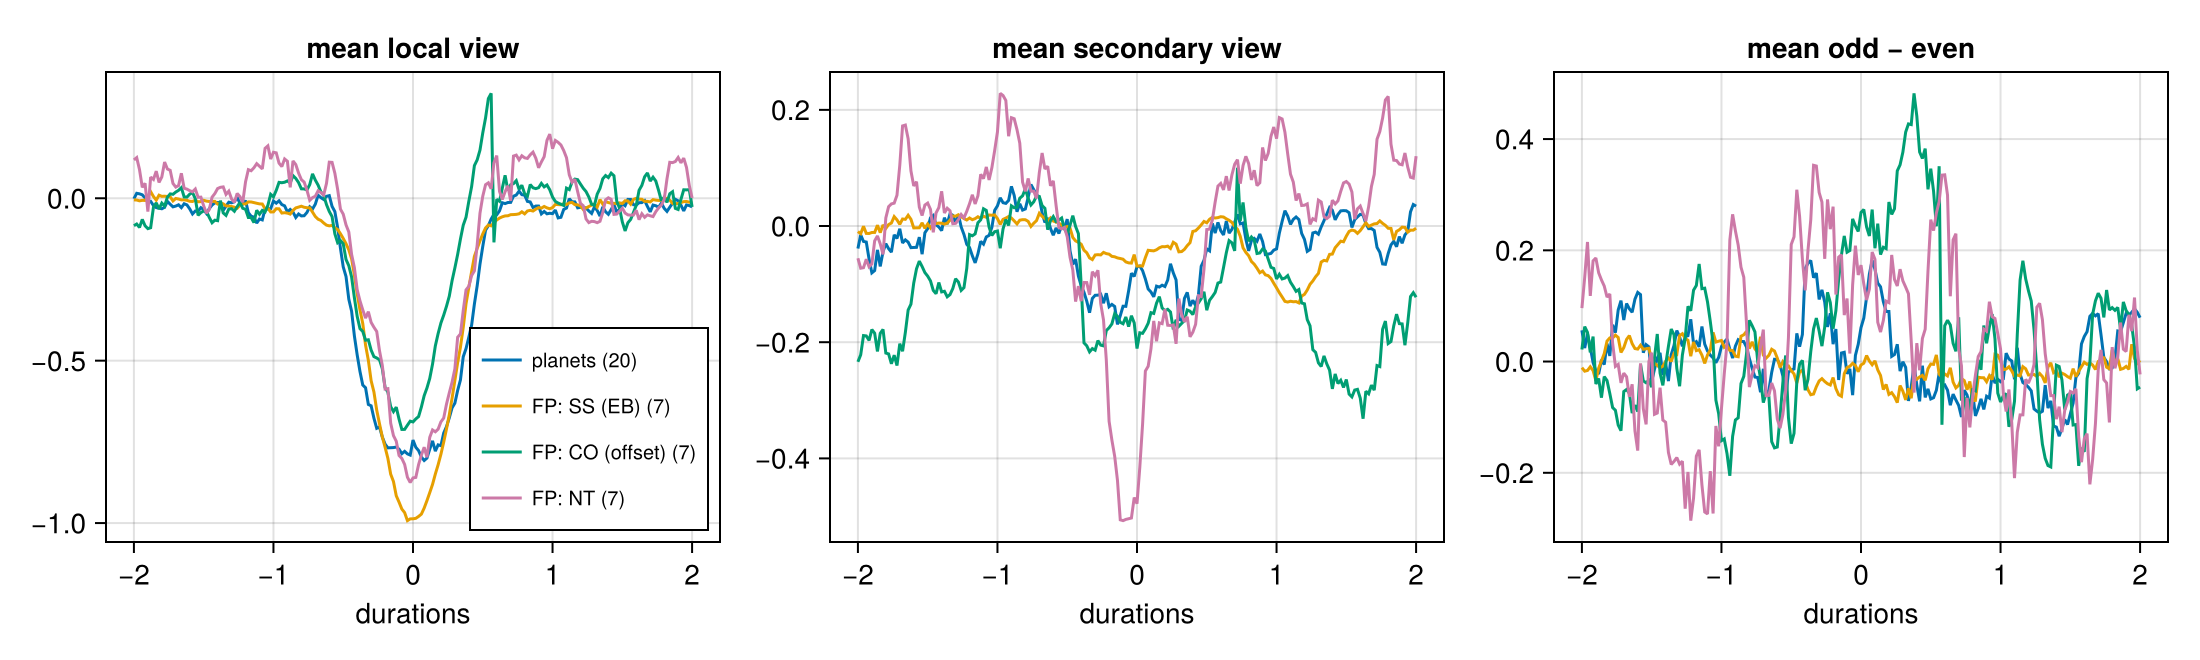

In [5]:
names_by_cat = Dict(c => [n for n in picks.kepoi_name[picks.category .== c] if haskey(views, n)] for c in unique(picks.category))
groups = [("planets", vcat((names_by_cat[c] for c in ["CONFIRMED", "CANDIDATE", "USP planet", "Long-P planet"])...)),
          ("FP: SS (EB)", names_by_cat["FP: SS (EB)"]), ("FP: CO (offset)", names_by_cat["FP: CO (offset)"]),
          ("FP: NT", names_by_cat["FP: NT"])]
fig = Figure(size = (1100, 330))
xl = range(-LOCAL_SPAN, LOCAL_SPAN; length = N_LOCAL)
for (j, f) in enumerate([:local_view, :secondary, (v -> v.odd .- v.even)])
    ax = Axis(fig[1, j]; title = ["mean local view", "mean secondary view", "mean odd − even"][j], xlabel = "durations")
    for (g, ns) in groups
        lines!(ax, xl, mean(f isa Symbol ? getfield(views[n], f) : f(views[n]) for n in ns); label = "$g ($(length(ns)))")
    end
    j == 1 && axislegend(ax; position = :rb, labelsize = 10)
end
fig

## 5. Centroid views ("+ centroid" family only)
In-transit shift of the flux-weighted centroid (column and row, pixels, relative to out of transit). A background
eclipsing binary that is offset from the target pulls the centroid during transit; an on-target planet does not.
Shown per KOI as the larger of the two in-transit shifts.

In [6]:
cshift(v) = maximum(abs, [mean(v.cen1[95:107]), mean(v.cen2[95:107])])
cs = DataFrame(group = String[], koi = String[], shift_mpix = Float64[])
for (g, ns) in groups, n in ns
    push!(cs, (g, n, 1e3 * cshift(views[n])))
end
combine(groupby(cs, :group), :shift_mpix => median => :median_shift_mpix, :shift_mpix => maximum => :max_shift_mpix,
        nrow => :kois)

Row,group,median_shift_mpix,max_shift_mpix,kois
,String,Float64,Float64,Int64
1,planets,0.0415492,6.18703,20
2,FP: SS (EB),0.937425,8.28857,7
3,FP: CO (offset),0.771187,12.8241,7
4,FP: NT,0.0623051,1.45013,7


## 6. QA columns per KOI
Number of observed transits, empty-bin fractions, and noise. KOIs with < 2 observed transits will get a QA flag in M2.

In [7]:
qa = DataFrame(koi = collect(keys(views)), n_transits = [v.n_transits for v in values(views)],
               empty_local = [v.empty_local for v in values(views)], empty_global = [v.empty_global for v in values(views)],
               depth_ppm = [round(Int, 1e6 * v.depth) for v in values(views)], sigma_ppm = [round(Int, 1e6 * v.sigma) for v in values(views)])
@printf("KOIs %d | < 2 transits %d | median empty local %.2f, global %.2f\n", nrow(qa), count(<(2), qa.n_transits),
        median(qa.empty_local), median(qa.empty_global))
sort(qa, :n_transits)[1:8, :]

KOIs 71 | < 2 transits 1 | median empty local 0.00, global 0.00


Row,koi,n_transits,empty_local,empty_global,depth_ppm,sigma_ppm
,String,Int64,Float64,Float64,Int64,Int64
1,K02360.01,0,0.263682,0.136432,90,324
2,K07848.01,3,0.0,0.0,1064,244
3,K08207.01,4,0.0,0.0,1483,636
4,K08063.01,4,0.0,0.0,692,405
5,K07911.01,4,0.0,0.0,521,454
6,K04030.02,5,0.0,0.0,1264,830
7,K01375.01,5,0.0,0.0,2398,133
8,K05535.01,6,0.0,0.0,1175,574


## 7. M0 findings and gate

**Gate: passed.** All 49 stars downloaded with no errors (median 17 quarters each), and every one of their 71 KOIs
got views. The full download (M1) is cheaper than planned: about **2.3 h** at ~1 s per star (4 parallel requests),
**55 GB** raw, which streams into a **~15 GB** cache (raw FITS deleted per star). The cache is above the plan's
5–10 GB guess because it keeps flux errors and both centroid columns; 370 GB are free, so this is fine. Detrending
+ views take ~1.4 s per star, ~3 h for everything in one process (less with 2 processes).

**The views look right by eye**, with these caveats carried into M2:
- The detrending follows strong stellar variability (K01786, ~10% swings) and leaves flat light curves.
- EB vs planet shape is visible: the SS average is V-shaped and deeper-centred, the planet average is U-shaped.
- **Transit-timing variations smear the folded transit** (K00377.01 = Kepler-9 b: the local view shows several
  offset dips). The linear catalog ephemeris cannot fix this; it should become a QA feature (scatter of individual
  transit times) rather than something to model away.
- **Wide eclipses:** the catalog duration often underestimates V-shaped EB eclipses, so their wings spill past the
  1.5-duration mask. The first version of the secondary search picked these wings up as a "secondary"; it now
  searches ≥ 3 durations from the transit (P/4 for short orbits). Secondary views of KOIs whose secondary is close
  to the transit still show the primary's edge, which is honest context.
- The deepest off-transit dip is always somewhat negative, even for planets (noise). Phase 2a features must use its
  **significance**, not its depth.
- Centroid views separate as expected: median in-transit shift ~0.04–0.06 mpix for planets and NT FPs, ~0.8–0.9 mpix
  for CO and SS FPs.
- One KOI (K02360.01) has **no observed transit** in the long-cadence data; it will get the M2 QA flag.

**Next:** M1, the full download of all 7,927 stars (pool + test; test stars are processed by the same code but their
labels are not looked at), at below-normal priority.